In [ ]:
!pip install scikit-learn joblib wordcloud

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from collections import Counter
import seaborn as sns
import re
import joblib
import string
from wordcloud import WordCloud

In [ ]:
fake = pd.read_csv('/content/fake_news2.csv',sep=';') # or 'iso-8859-1'
real = pd.read_csv('/content/real_news2.csv',sep=';')

In [ ]:
fake.head()

,judul_berita,waktu_berita_detail,label
0,Bantuan dari Pemerintah untuk TKI,06/05/2025,0
1,Dedi Mulyadi Sebut Orang yang Ragukan Ijazah J...,06/05/2025,0
2,Video Netanyahu Mengecam Presiden Prabowo,06/05/2025,0
3,Akun Facebook Tawarkan Bantuan Benih Ikan dari...,06/05/2025,0
4,PLN Bagikan Token Listrik Gratis Rp200.000,05/05/2025,0


In [ ]:
real.head()

,judul_berita,waktu_berita_detail,label
0,Katy Perry dan Awak Perempuan Akhirnya Menembu...,14/04/2025,1
1,Tiga Bocah Jadi Korban Pencabulan Guru Hadroh ...,14/04/2025,1
2,"2 Rumah La Nyalla di Surabaya Digeledah KPK, B...",14/04/2025,1
3,Pengguna MyPertamina Meningkat Selama Masa Sat...,14/04/2025,1
4,Stres Bikin Asam Lambung Naik? Ini Penjelasan ...,14/04/2025,1


In [ ]:
data = pd.concat([fake,real], axis =0 )
data.drop(["waktu_berita_detail"], axis = 1, inplace = True)

data.sample(10)

,judul_berita,label
10169,Ridwan Kamil Tak Laporkan Motor Royal Enfield ...,1
10218,Pembunuh Pria Dalam Karung di Tangerang Menyes...,1
11583,GWM Hadirkan Kokpit Cerdas Coffe OS 3 di Kabin...,1
8197,Bupati Lumajang Beri Bantuan Lewat Whatsapp,0
14646,"Harga iPhone 16e, iPhone 16 Pro, dan iPhone 16...",1
14284,"Isu Ijazah Palsu Jokowi Memanas, 4 Nama Dilapo...",1
7278,Penemuan Iphone Penumpang Pesawat Sriwijaya,0
11766,Prakiraan Cuaca Makassar Hari Ini Minggu 27 Ap...,1
6522,"SBN Syariah SR022 Terbit 16 Mei 2025, Ini Cara...",1
4799,Pilu Warga Bekasi: Dipekerjakan Jadi Scammer d...,1


In [ ]:
data.reset_index(inplace = True)
data.drop(["index"], axis = 1, inplace = True)

data.sample(10)

,judul_berita,label
15036,"Wall Street Terkoreksi, Investor Cermati Lapor...",1
14945,Resep Cupcake 2 Telur untuk Menyambut Paskah d...,1
9138,Email yang Berisi Surat Panggilan Tes Calon Ka...,0
21825,IKM UI Desak TNI Hentikan Intervensi dan Provo...,1
4522,Akun Facebook Mengatasnamakan Wakil Bupati Kuk...,0
15364,"Dua Geng Motor Tawuran di Kuburan Cina Jambi, ...",1
24109,Keberangkatan Malam PO Juragan99 Trans Dimulai,1
1641,Akun Facebook Mengatasnamakan Wakil Ketua DPR ...,0
22949,Koalisi Pejalan Kaki Tolak Jalur Sepeda di Ata...,1
8243,Angka Perceraian Melonjak Drastis selama Pande...,0


([<matplotlib.patches.Wedge at 0x7a3009fa4e50>,
 [Text(-1.1839054259307724, -0.19587736584832005, 'Fake'),
  Text(1.1839053154048336, 0.19587803387869135, 'Real')],
 [Text(-0.6906114984596171, -0.11426179674485334, '55.2%'),
  Text(0.6906114339861529, 0.11426218642923662, '44.8%')])

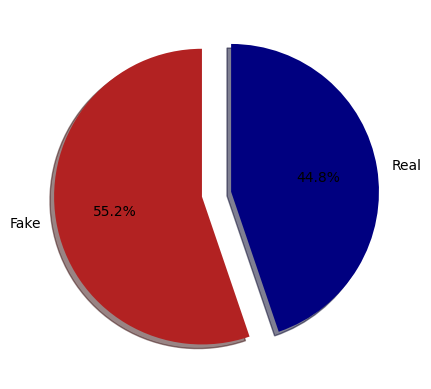

In [ ]:
label_size = [data['label'].sum(),len(data['label'])-data['label'].sum()]
plt.pie(label_size,explode=[0.1,0.1],colors=['firebrick','navy'],startangle=90,shadow=True,labels=['Fake','Real'],autopct='%1.1f%%')

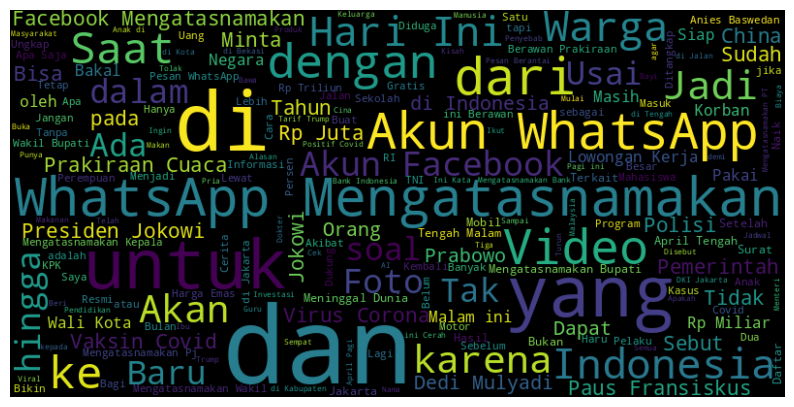

In [ ]:
all_text = " ".join(data['judul_berita'])

wordcloud = WordCloud(width=800, height=400, random_state=21, max_font_size=110).generate(all_text)

plt.figure(figsize=(10, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis('off')
plt.title('Word Cloud - Real News')
plt.show()

In [ ]:
fake_text = " ".join(data[data['label'] == 0]['judul_berita']) # Assuming 0 is for fake
real_text = " ".join(data[data['label'] == 1]['judul_berita']) # Assuming 1 is for real


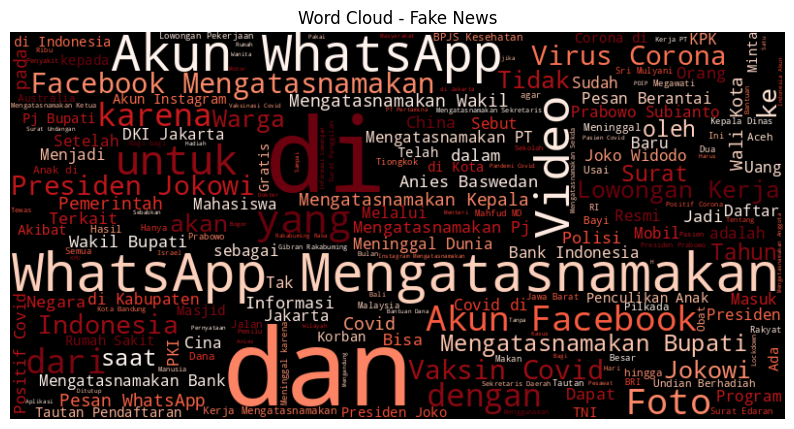

In [ ]:
wordcloud_fake = WordCloud(width=800, height=400, random_state=21, max_font_size=110, colormap='Reds').generate(fake_text)

plt.figure(figsize=(10, 7))
plt.imshow(wordcloud_fake, interpolation="bilinear")
plt.axis('off')
plt.title('Word Cloud - Fake News')
plt.show()

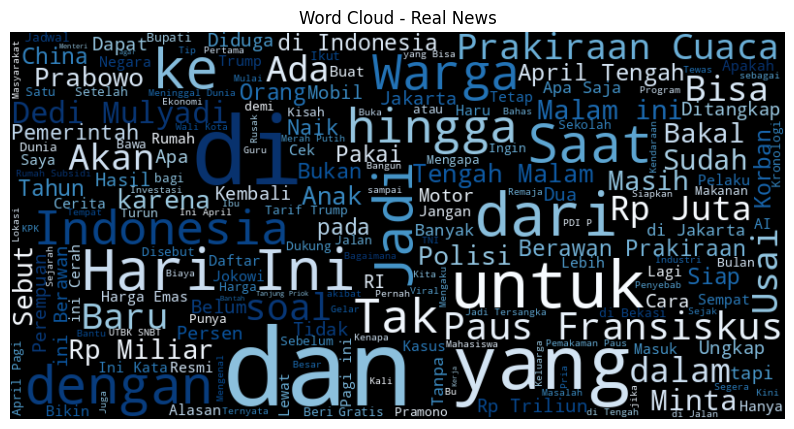

In [ ]:
wordcloud_real = WordCloud(width=800, height=400, random_state=21, max_font_size=110, colormap='Blues').generate(real_text)

plt.figure(figsize=(10, 7))
plt.imshow(wordcloud_real, interpolation="bilinear")
plt.axis('off')
plt.title('Word Cloud - Real News')
plt.show()

In [ ]:
# prompt: buatkan visual yang dapat memperlihat jumlah setiap kata yang muncul

import matplotlib.pyplot as plt
from collections import Counter

# Function to plot word frequency
def plot_word_frequency(text, title, num_words=20):
    # Split text into words
    words = text.split()

    # Count word frequencies
    word_counts = Counter(words)

    # Get the most common words
    most_common_words = word_counts.most_common(num_words)

    # Prepare data for plotting
    words, counts = zip(*most_common_words)

    # Create bar plot
    plt.figure(figsize=(12, 6))
    sns.barplot(x=list(counts), y=list(words), palette='viridis')
    plt.title(title)
    plt.xlabel('Frequency')
    plt.ylabel('Words')
    plt.show()

# Plot word frequency for all headlines
plot_word_frequency(all_text, 'Top 20 Word Frequency - All Headlines')

# Plot word frequency for fake news headlines
plot_word_frequency(fake_text, 'Top 20 Word Frequency - Fake News Headlines')

# Plot word frequency for real news headlines
plot_word_frequency(real_text, 'Top 20 Word Frequency - Real News Headlines')

In [ ]:
x = data['judul_berita']
y = data['label']

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42)

In [ ]:
print("Jumlah data training:", len(x_train))
print("Jumlah data testing:", len(x_test))
print("Jumlah target training:", len(y_train))
print("Jumlah target testing:", len(y_test))

Jumlah data training: 19917
Jumlah data testing: 6639
Jumlah target training: 19917
Jumlah target testing: 6639


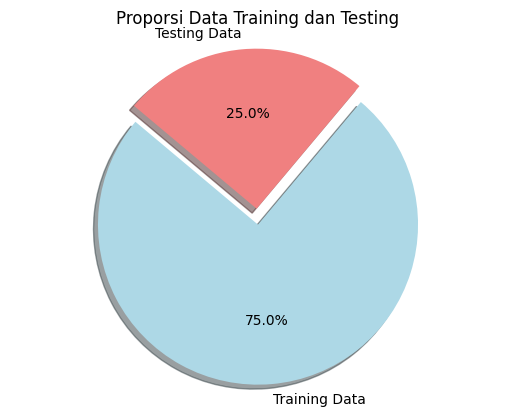

In [ ]:
import matplotlib.pyplot as plt

# Data untuk pie chart
labels = ['Training Data', 'Testing Data']
sizes = [len(x_train), len(x_test)]
colors = ['lightblue', 'lightcoral']
explode = (0.1, 0)  # Explode 1st slice

# Membuat pie chart
plt.pie(sizes, explode=explode, labels=labels, colors=colors,
        autopct='%1.1f%%', shadow=True, startangle=140)

plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.title('Proporsi Data Training dan Testing')
plt.show()

In [ ]:
vectorizer = TfidfVectorizer()
xv_train = vectorizer.fit_transform(x_train) # Fit dan transform data training
xv_test = vectorizer.transform(x_test)

In [ ]:
lr = LogisticRegression()
lr.fit(xv_train,y_train)

LogisticRegression()

In [ ]:
pred_lr=lr.predict(xv_test)
lr.score(xv_test, y_test)

0.9272480795300497

In [ ]:
print(classification_report(y_test, pred_lr))

              precision    recall  f1-score   support

           0       0.96      0.87      0.91      2971
           1       0.90      0.97      0.94      3668

    accuracy                           0.93      6639
   macro avg       0.93      0.92      0.93      6639
weighted avg       0.93      0.93      0.93      6639



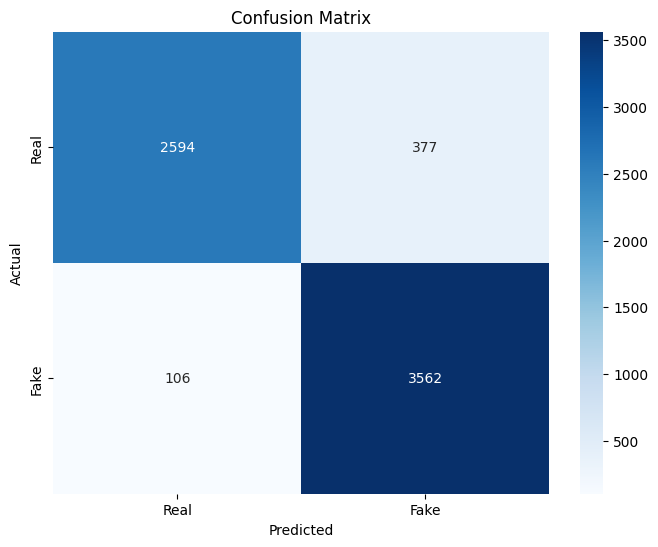

In [ ]:
cm = confusion_matrix(y_test, pred_lr)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()